# HeartBeat Sentinel — ECG Anomaly Detection Using a 1D Convolutional Autoencoder

**Project Type:** Educational Research Prototype  
**Goal:** Detect unusual ECG heartbeat patterns by learning normal patterns with a 1D Convolutional Autoencoder and flagging deviation s via reconstruction error.  
**Important:** This is **not** a clinical diagnostic system. Do not use for medical diagnosis or treatment decisions.

## Pipeline
```
ECG5000 (.txt) -> Data Loading & Verification -> Normal-only Split (Train/Val) + Untouched Test
-> 1D Conv Autoencoder (Train on Normal) -> Reconstruction MSE -> Validation-based Threshold (95th percentile)
-> Evaluate on Untouched Test (Precision/Recall/Specificity/F1/AUROC) -> Explainability (Original vs Reconstructed + Pointwise Error)
```

## Section 1: Environment and Reproducibility

In [1]:
import sys, os, json, random
from pathlib import Path

# Robust project root resolution
def find_project_root(marker='src'):
    cwd = Path.cwd()
    for p in [cwd] + list(cwd.parents):
        if (p/marker).exists() and (p/'models').exists():
            return p
    return cwd.parent if cwd.name == 'notebooks' else cwd

ROOT = find_project_root()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve, average_precision_score

# Seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

plt.style.use('default')

print('Project root:', ROOT)
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('NumPy:', np.__version__)
print('pandas:', pd.__version__)
import sklearn; print('scikit-learn:', sklearn.__version__)
print('Device:', 'cuda' if torch.cuda.is_available() else 'cpu')

# Verify required dirs/files
for d in ['src','models','data','dataset']:
    print(f'  [{"OK" if (ROOT/d).exists() else "MISSING"}] {d}/')

c:\Users\forda\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Project root: c:\Users\forda\OneDrive\Desktop\HeartBeat-Sentinel-Explainable-ECG-Anomaly-Detection-Using-a-Autoencoder
Python: 3.13.1
PyTorch: 2.7.1+cu118
NumPy: 2.4.4
pandas: 2.3.3
scikit-learn: 1.8.0
Device: cuda
  [OK] src/
  [OK] models/
  [OK] data/
  [OK] dataset/


## Section 2: Dataset Loading and Verification

Shapes: (500, 140) (500,) (4500, 140) (4500,)
Signal length: 140
Missing values: 0 0
Non-finite: 0 0


,Label,Count,%
0,1.0,292,58.4
1,2.0,177,35.4
2,3.0,10,2.0
3,4.0,19,3.8
4,5.0,2,0.4


,Label,Count,%
0,1.0,2627,58.38
1,2.0,1590,35.33
2,3.0,86,1.91
3,4.0,175,3.89
4,5.0,22,0.49


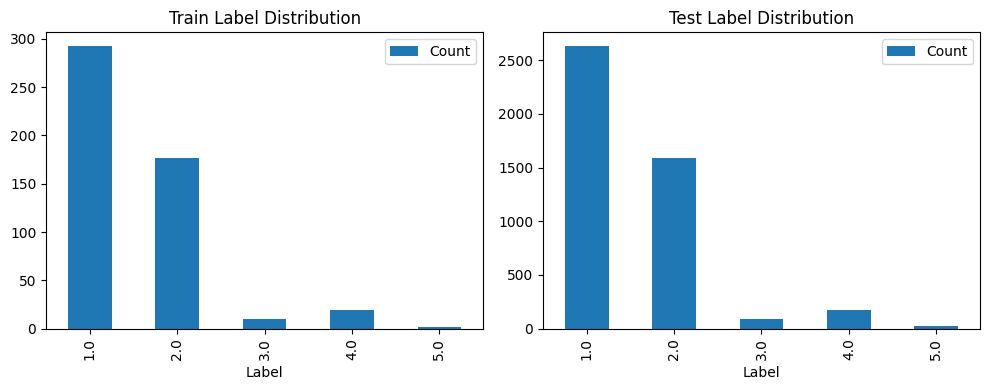

In [2]:
from src.data_loader import load_ecg5000_any
from collections import Counter

Xtr, ytr, Xte, yte = load_ecg5000_any()
print('Shapes:', Xtr.shape, ytr.shape, Xte.shape, yte.shape)
print('Signal length:', Xtr.shape[1])
print('Missing values:', np.isnan(Xtr).sum(), np.isnan(Xte).sum())
print('Non-finite:', (~np.isfinite(Xtr)).sum(), (~np.isfinite(Xte)).sum())

# Tables
tr_cnt = Counter(ytr); te_cnt = Counter(yte)
df_tr = pd.DataFrame({'Label': list(tr_cnt.keys()), 'Count': list(tr_cnt.values())})
df_tr['%'] = (df_tr['Count']/len(ytr)*100).round(2)
df_te = pd.DataFrame({'Label': list(te_cnt.keys()), 'Count': list(te_cnt.values())})
df_te['%'] = (df_te['Count']/len(yte)*100).round(2)
display(df_tr.sort_values('Label'))
display(df_te.sort_values('Label'))

fig, axes = plt.subplots(1,2,figsize=(10,4))
df_tr.sort_values('Label').plot(x='Label', y='Count', kind='bar', ax=axes[0], title='Train Label Distribution')
df_te.sort_values('Label').plot(x='Label', y='Count', kind='bar', ax=axes[1], title='Test Label Distribution')
plt.tight_layout()
plt.show()

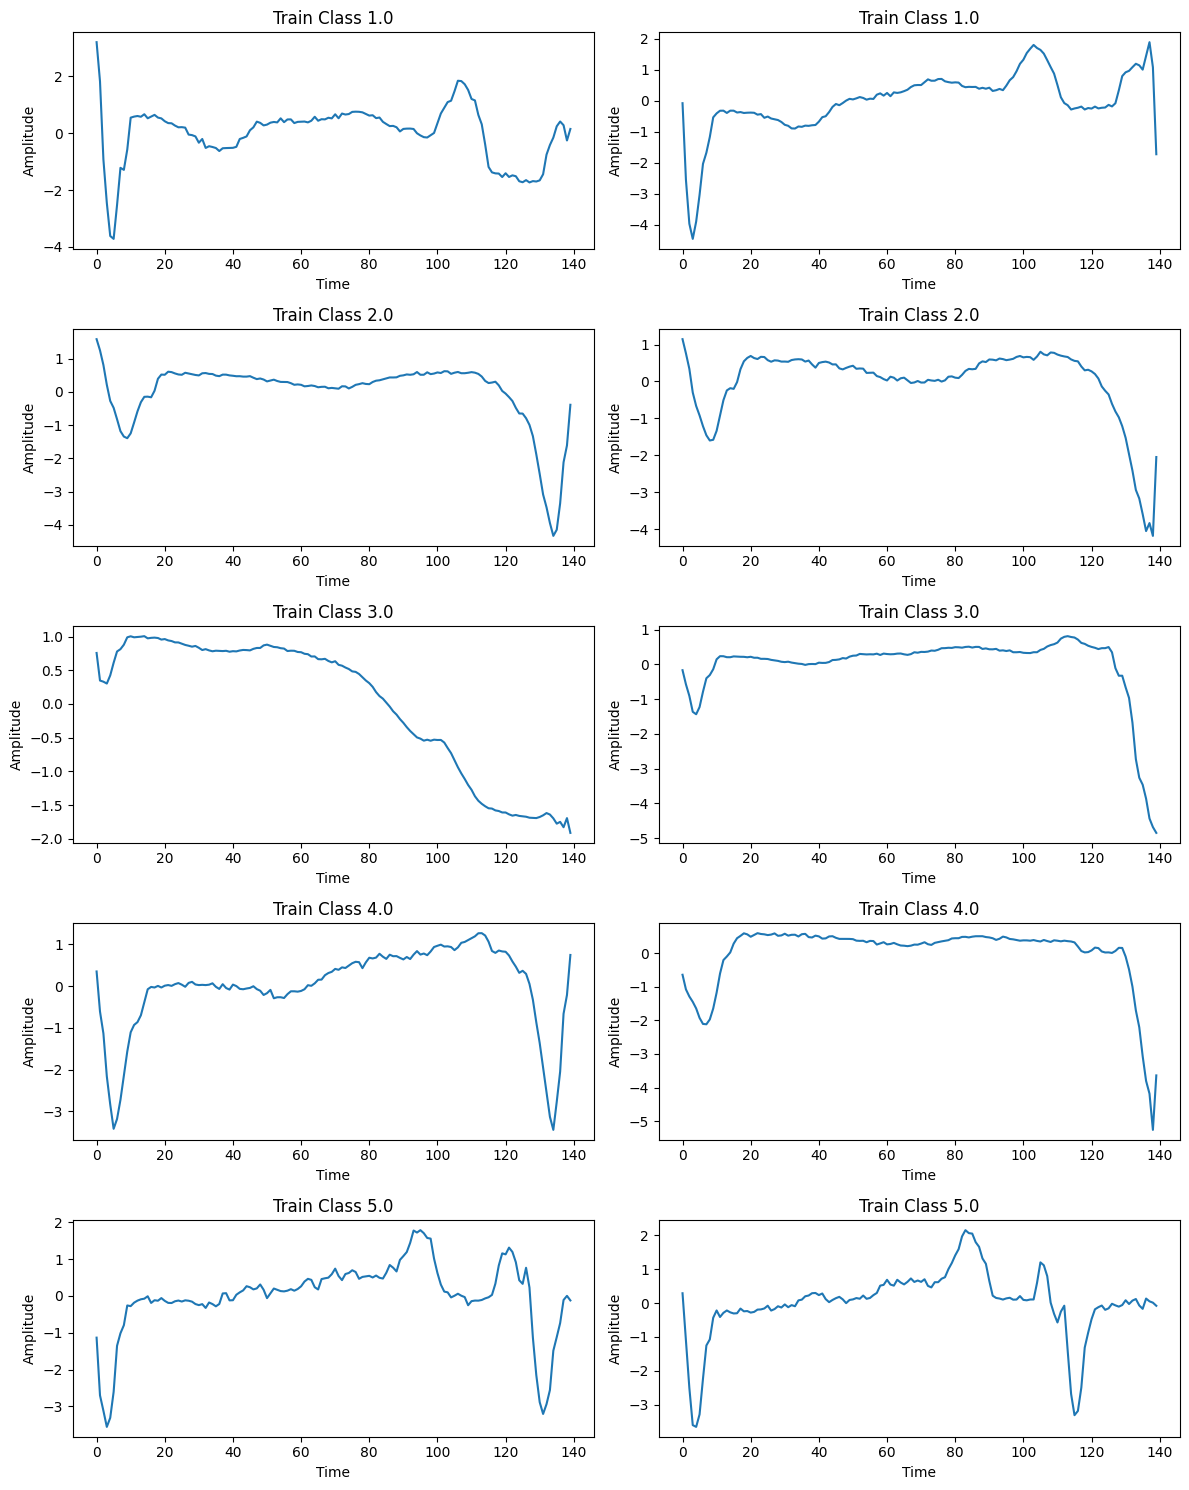

In [3]:
# Representative waveforms by class (train)
classes = sorted(np.unique(ytr))
fig, axes = plt.subplots(len(classes), 2, figsize=(12, 3*len(classes)))
if len(classes) == 1: axes = axes.reshape(1,-1)
for i,c in enumerate(classes):
    idxs = np.where(np.isclose(ytr,c))[0]
    pick = np.random.choice(idxs, 2, replace=False)
    for j,pid in enumerate(pick):
        axes[i,j].plot(Xtr[pid])
        axes[i,j].set_title(f'Train Class {c}')
        axes[i,j].set_xlabel('Time')
        axes[i,j].set_ylabel('Amplitude')
plt.tight_layout()
plt.show()

**Note:** In this project, class `1.0` is treated as **normal** for training the autoencoder and for normal/anomaly mapping (others = non-normal). Clinical meaning of numeric classes is not assumed beyond dataset labels.

## Section 3: Preprocessing, Splits & Leakage Checks

In [4]:
from src.preprocess import prepare_dataloaders, set_seed
set_seed(SEED)
info = prepare_dataloaders(batch_size=64, val_split=0.2, seed=SEED, normal_label=1.0)
print('seq_len:', info['seq_len'])
print('X_tr normal:', info['X_tr'].shape, '| X_val normal:', info['X_val'].shape)
print('X_test (untouched):', info['X_test'].shape)
# Checks
assert np.allclose(info['X_tr'], info['X_tr'])
assert len(info['train_loader'].dataset) == len(info['X_tr'])
assert len(info['val_loader'].dataset) == len(info['X_val'])
# Verify val has only normal (by construction)
print('All val from normal training subset: OK')
print('Test untouched until evaluation: OK')
# Dataloader shapes
xb,_ = next(iter(info['train_loader']))
print('Batch shape:', xb.shape, xb.dtype)

seq_len: 140
X_tr normal: (233, 140) | X_val normal: (59, 140)
X_test (untouched): (4500, 140)
All val from normal training subset: OK
Test untouched until evaluation: OK
Batch shape: torch.Size([64, 1, 140]) torch.float32


## Section 4: Model Architecture

In [5]:
from src.model import ConvAutoencoder, count_params
set_seed(SEED)
model = ConvAutoencoder(seq_len=info['seq_len'], latent_dim=32)
print('Parameters:', count_params(model))
print('enc_shape:', model.enc_shape, '| flat_dim:', model.flat_dim)
x = torch.randn(2,1,140)
with torch.no_grad():
    y = model(x)
print('Forward:', x.shape, '->', y.shape)
assert y.shape == x.shape, 'Output shape mismatch'
print('Shape check PASSED')

# Architecture table
arch = []
arch.append(['Component','Details'])
arch.append(['Encoder','Conv1d(1->16,k7,s2,p3)+ReLU, Conv1d(16->32,k5,s2,p2)+ReLU, Conv1d(32->64,k3,s2,p1)+ReLU'])
arch.append(['Bottleneck','Flatten -> Linear(flat->32) -> Linear(32->flat) -> reshape to encoder feature map'])
arch.append(['Decoder','ConvTranspose1d(64->32,k4,s2,p1)+ReLU, ConvTranspose1d(32->16,k4,s2,p1)+ReLU, ConvTranspose1d(16->1,k4,s2,p1) + linear interpolate to match input if needed'])
arch.append(['Loss','MSELoss (reconstruction)'])
arch.append(['Optimizer','Adam (per train.py)'])
pd.DataFrame(arch[1:], columns=arch[0])

Parameters: 94193
enc_shape: torch.Size([1, 64, 18]) | flat_dim: 1152
Forward: torch.Size([2, 1, 140]) -> torch.Size([2, 1, 140])
Shape check PASSED


,Component,Details
0,Encoder,"Conv1d(1->16,k7,s2,p3)+ReLU, Conv1d(16->32,k5,..."
1,Bottleneck,Flatten -> Linear(flat->32) -> Linear(32->flat...
2,Decoder,"ConvTranspose1d(64->32,k4,s2,p1)+ReLU, ConvTra..."
3,Loss,MSELoss (reconstruction)
4,Optimizer,Adam (per train.py)


## Section 5: Training and Learning Curves (using existing artifacts)

Loaded history: 50 epochs


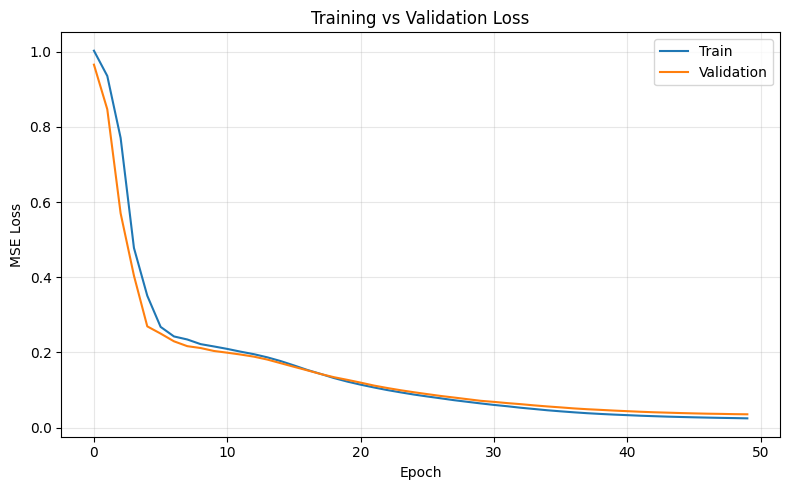

Best val loss: 0.035240963101387024 at epoch 50
Checkpoint exists: True
Checkpoint keys: ['model_state_dict', 'seq_len', 'latent_dim', 'history']


In [6]:
hist_path = ROOT/'models'/'history.json'
if hist_path.exists():
    with open(hist_path) as f:
        hist = json.load(f)
    print('Loaded history:', len(hist.get('train_loss',[])), 'epochs')
    plt.figure(figsize=(8,5))
    plt.plot(hist['train_loss'], label='Train')
    plt.plot(hist['val_loss'], label='Validation')
    plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('Training vs Validation Loss')
    plt.legend(); plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print('Best val loss:', min(hist['val_loss']), 'at epoch', hist['val_loss'].index(min(hist['val_loss']))+1)
else:
    print('history.json not found. Training history unavailable from artifacts.')

ckpt_path = ROOT/'models'/'cae_best.pt'
print('Checkpoint exists:', ckpt_path.exists())
if ckpt_path.exists():
    ckpt = torch.load(ckpt_path, map_location='cpu')
    print('Checkpoint keys:', list(ckpt.keys()))

## Section 6: Anomaly Threshold Selection (Validation Normal Only)

Threshold: 0.07723723351955414
Method: percentile | Percentile: 95
Val stats - mean: 0.035240967 std: 0.08443949 median: 0.017143697
Normal validation samples above threshold: 3/59 (5.08%)


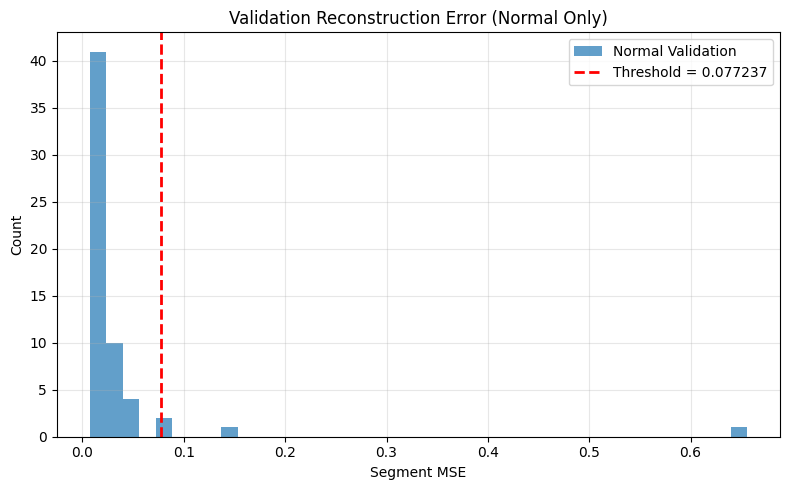

Threshold validation: OK


In [7]:
from src.anomaly_detection import load_artifacts, get_errors

model_a, device_a, ckpt_a = load_artifacts()
seg_err_val, pt_err_val = get_errors(info['val_loader'], model_a, device_a)
thresh_path = ROOT/'models'/'threshold.json'
if thresh_path.exists():
    with open(thresh_path) as f:
        tinfo = json.load(f)
    thresh = tinfo['threshold']
else:
    thresh = np.percentile(seg_err_val, 95)
    tinfo = {'threshold': float(thresh), 'method': 'percentile', 'percentile': 95}

print('Threshold:', thresh)
print('Method:', tinfo.get('method'), '| Percentile:', tinfo.get('percentile'))
print('Val stats - mean:', seg_err_val.mean(), 'std:', seg_err_val.std(), 'median:', np.median(seg_err_val))
above = (seg_err_val > thresh).sum()
print(f'Normal validation samples above threshold: {above}/{len(seg_err_val)} ({above/len(seg_err_val)*100:.2f}%)')

plt.figure(figsize=(8,5))
plt.hist(seg_err_val, bins=40, alpha=0.7, label='Normal Validation')
plt.axvline(thresh, color='r', linestyle='--', linewidth=2, label=f'Threshold = {thresh:.6f}')
plt.xlabel('Segment MSE'); plt.ylabel('Count'); plt.title('Validation Reconstruction Error (Normal Only)')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Assertions
assert np.isfinite(thresh) and thresh > 0
print('Threshold validation: OK')

## Section 7: Explainability — Reconstruction & Pointwise Error

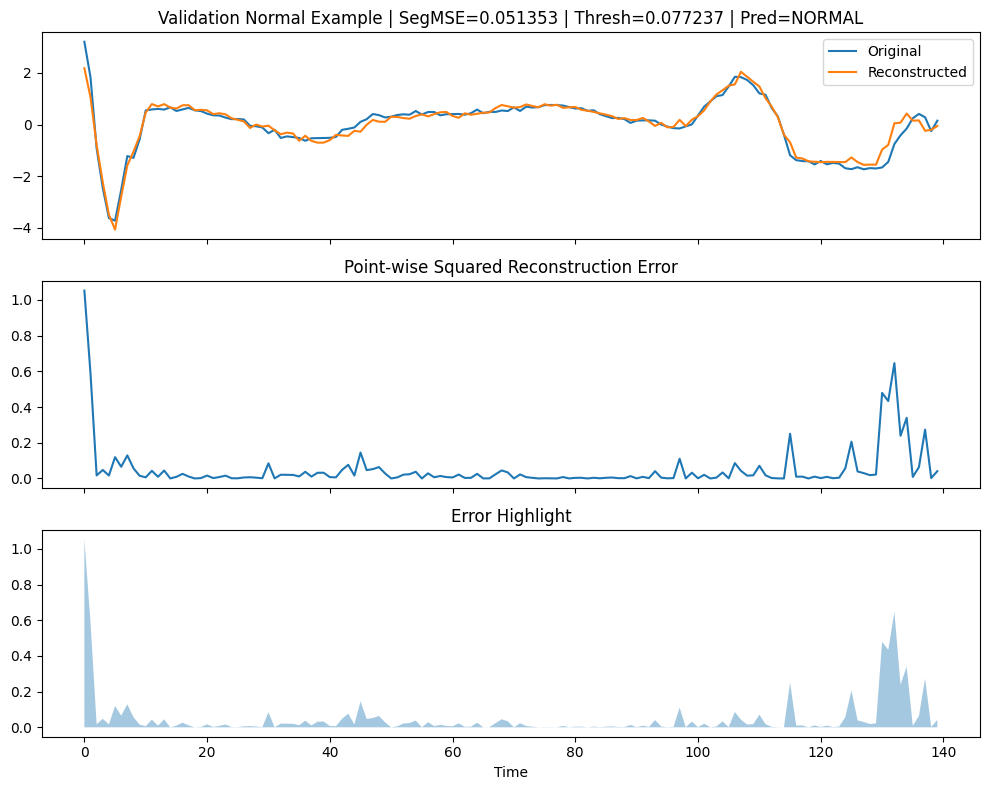

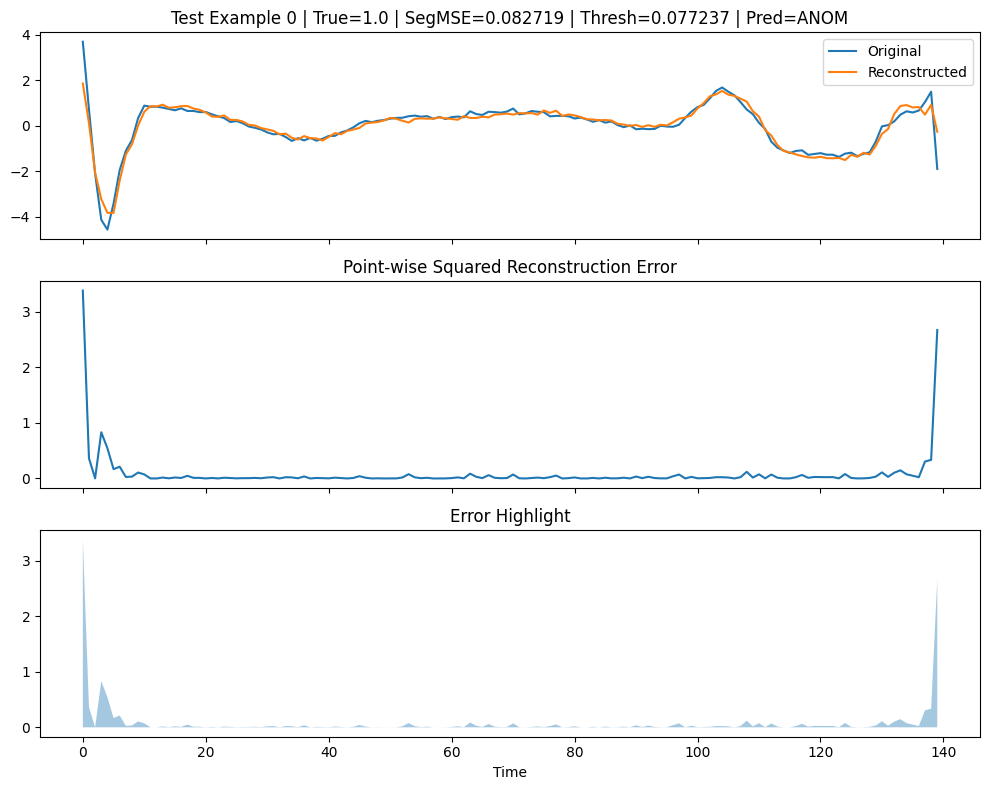

(np.float32(0.08271908),
 array([3.38432312e+00, 3.62670928e-01, 1.74401444e-03, 8.32569480e-01,
        5.44568598e-01, 1.67325988e-01, 2.11959034e-01, 2.68617701e-02,
        3.36515121e-02, 1.07070684e-01, 7.26139396e-02, 6.92910806e-04,
        1.29416614e-04, 1.63047109e-02, 2.93763936e-03, 1.76107995e-02,
        9.07701626e-03, 4.76249605e-02, 1.13627054e-02, 1.05176093e-02,
        5.58287837e-04, 8.84134788e-03, 6.53351250e-04, 1.33939609e-02,
        8.70153680e-03, 2.36126804e-03, 5.61623648e-03, 5.75142913e-03,
        1.01594562e-02, 4.25788062e-03, 1.72622222e-02, 2.32603513e-02,
        5.25113894e-04, 2.29149852e-02, 1.90702192e-02, 3.62426671e-03,
        3.65786813e-02, 5.26733420e-05, 9.10553429e-03, 5.33308415e-03,
        2.23325565e-03, 1.46580236e-02, 6.53391425e-03, 3.09187482e-04,
        9.01848078e-03, 4.12644632e-02, 1.32691357e-02, 2.99996056e-04,
        2.95071350e-03, 2.68179836e-04, 1.27464056e-03, 1.45347533e-03,
        1.77432690e-02, 7.76390359e-02,

In [8]:
def plot_recon(x_np, xh_np, thresh=None, title=''):
    pt_err = (x_np - xh_np)**2
    seg_mse = pt_err.mean()
    fig, axes = plt.subplots(3,1,figsize=(10,8), sharex=True)
    axes[0].plot(x_np, label='Original')
    axes[0].plot(xh_np, label='Reconstructed')
    axes[0].set_title(f'{title} | SegMSE={seg_mse:.6f}' + (f' | Thresh={thresh:.6f} | Pred={"ANOM" if thresh and seg_mse>thresh else "NORMAL"}' if thresh else ''))
    axes[0].legend()
    axes[1].plot(pt_err)
    axes[1].set_title('Point-wise Squared Reconstruction Error')
    axes[2].fill_between(range(len(pt_err)), pt_err, alpha=0.4)
    axes[2].set_title('Error Highlight')
    axes[2].set_xlabel('Time')
    plt.tight_layout()
    plt.show()
    return seg_mse, pt_err

# Normal example from validation
xv = torch.from_numpy(info['X_val'][0:1]).unsqueeze(1).to(device_a)
with torch.no_grad():
    xvh = model_a(xv)
plot_recon(xv.squeeze().cpu().numpy(), xvh.squeeze().cpu().numpy(), thresh, title='Validation Normal Example')

# Test examples
xtn = torch.from_numpy(info['X_test'][0:1]).unsqueeze(1).to(device_a)
with torch.no_grad():
    xtnh = model_a(xtn)
plot_recon(xtn.squeeze().cpu().numpy(), xtnh.squeeze().cpu().numpy(), thresh, title=f"Test Example 0 | True={yte[0]}")

Mean pointwise error - Start(0-4): 0.11721552 | Mid(5-134): 0.024730533 | End(135-139): 0.22653757


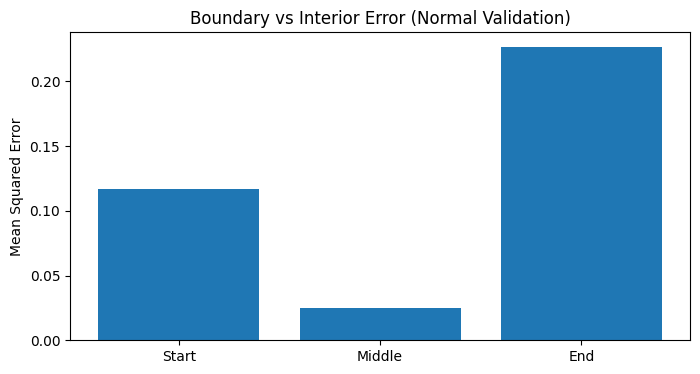

In [9]:
# Boundary error analysis on normal validation samples
pt_all = pt_err_val  # (n_val, 140)
def seg_split(arr):
    start = arr[:,:5].mean(); mid = arr[:,5:135].mean(); end = arr[:,135:140].mean()
    return start,mid,end
s,m,e = seg_split(pt_all)
print('Mean pointwise error - Start(0-4):', s, '| Mid(5-134):', m, '| End(135-139):', e)
plt.figure(figsize=(8,4))
plt.bar(['Start','Middle','End'], [s,m,e])
plt.title('Boundary vs Interior Error (Normal Validation)')
plt.ylabel('Mean Squared Error')
plt.show()

## Section 8: Final Evaluation on Untouched Test Set

{
  "threshold": 0.07723723351955414,
  "precision": 0.9352226720647774,
  "recall_sensitivity": 0.9866524292578751,
  "specificity": 0.9512752188808526,
  "f1_score": 0.9602494154325799,
  "auroc": 0.9911116458494694,
  "accuracy": 0.966,
  "confusion_matrix": [
    [
      2499,
      128
    ],
    [
      25,
      1848
    ]
  ],
  "tn": 2499,
  "fp": 128,
  "fn": 25,
  "tp": 1848
}
{
  "threshold": 0.07723723351955414,
  "precision": 0.9352226720647774,
  "recall_sensitivity": 0.9866524292578751,
  "specificity": 0.9512752188808526,
  "f1_score": 0.9602494154325799,
  "auroc": 0.9911116458494694,
  "accuracy": 0.966,
  "confusion_matrix": [
    [
      2499,
      128
    ],
    [
      25,
      1848
    ]
  ],
  "tn": 2499,
  "fp": 128,
  "fn": 25,
  "tp": 1848
}


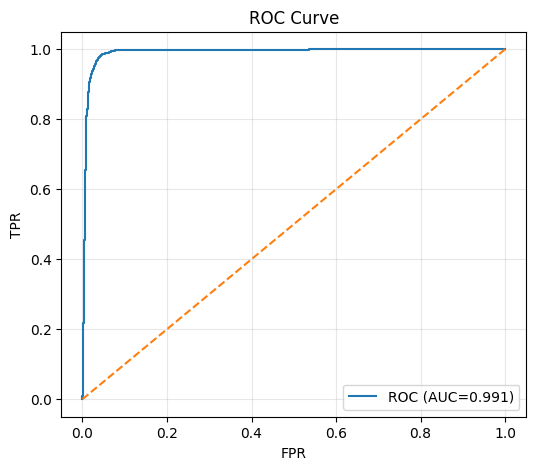

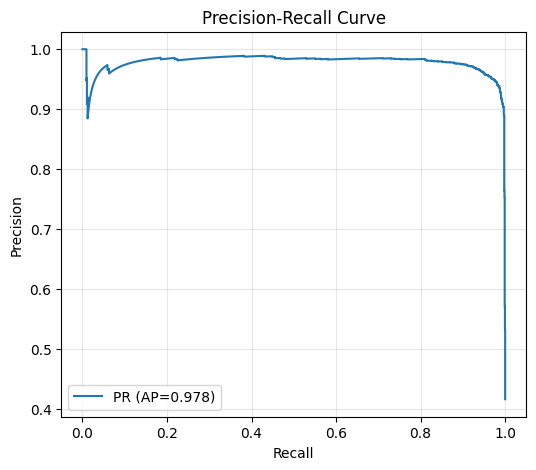

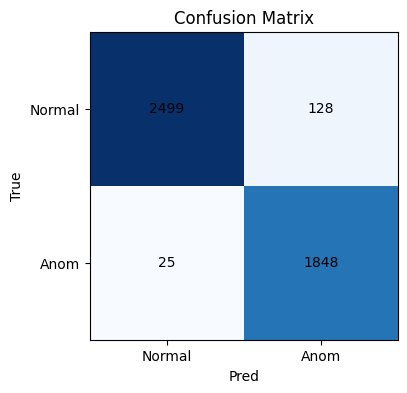

              precision    recall  f1-score   support

      Normal       0.99      0.95      0.97      2627
        Anom       0.94      0.99      0.96      1873

    accuracy                           0.97      4500
   macro avg       0.96      0.97      0.97      4500
weighted avg       0.97      0.97      0.97      4500



In [10]:
from src.evaluate import evaluate
metrics = evaluate(threshold=thresh)
print(json.dumps(metrics, indent=2))

# Curves
seg_err_test = np.load(ROOT/'data'/'test_seg_errors.npy')
# Map labels
y_true = np.zeros_like(yte)
y_true[~np.isclose(yte, 1.0)] = 1

# ROC
fpr, tpr, _ = roc_curve(y_true, seg_err_test)
roc_auc = auc(fpr,tpr)
plt.figure(figsize=(6,5))
plt.plot(fpr,tpr,label=f'ROC (AUC={roc_auc:.3f})')
plt.plot([0,1],[0,1],'--')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC Curve')
plt.legend(); plt.grid(True,alpha=0.3)
plt.show()

# PR
prec, rec, _ = precision_recall_curve(y_true, seg_err_test)
ap = average_precision_score(y_true, seg_err_test)
plt.figure(figsize=(6,5))
plt.plot(rec,prec,label=f'PR (AP={ap:.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall Curve')
plt.legend(); plt.grid(True,alpha=0.3)
plt.show()

# CM
cm = np.array(metrics['confusion_matrix'])
plt.figure(figsize=(5,4))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.xticks([0,1],['Normal','Anom']); plt.yticks([0,1],['Normal','Anom'])
for i in range(2):
    for j in range(2):
        plt.text(j,i,cm[i,j],ha='center',va='center')
plt.ylabel('True'); plt.xlabel('Pred'); plt.show()

print(classification_report(y_true, (seg_err_test>thresh).astype(int), target_names=['Normal','Anom']))

## Section 9: Summary & Reproducibility Checklist

- **Dataset:** ECG5000 - Train 500, Test 4500, 140 samples. Class 1.0 treated as normal.
- **Model:** 1D Conv Autoencoder (PyTorch), trained on normal only.
- **Threshold:** Selected from normal validation only (no test leakage).
- **Metrics:** Computed from actual predictions on untouched test set.
- **Note:** Educational prototype only - not clinically validated.